# distillation + gc analysis
simple distillation of an acetone/toluene mixture. experiments performed in a UT Austin lab. 


## setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from scipy.integrate import cumulative_trapezoid

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11})
COLORS = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
ACETONE, TOLUENE = "#2a78d6", "#eb6834"

curve = pd.read_csv("data/distillation_curve.csv")
gc = pd.read_csv("data/gc_results.csv")

## 1. distillation curve

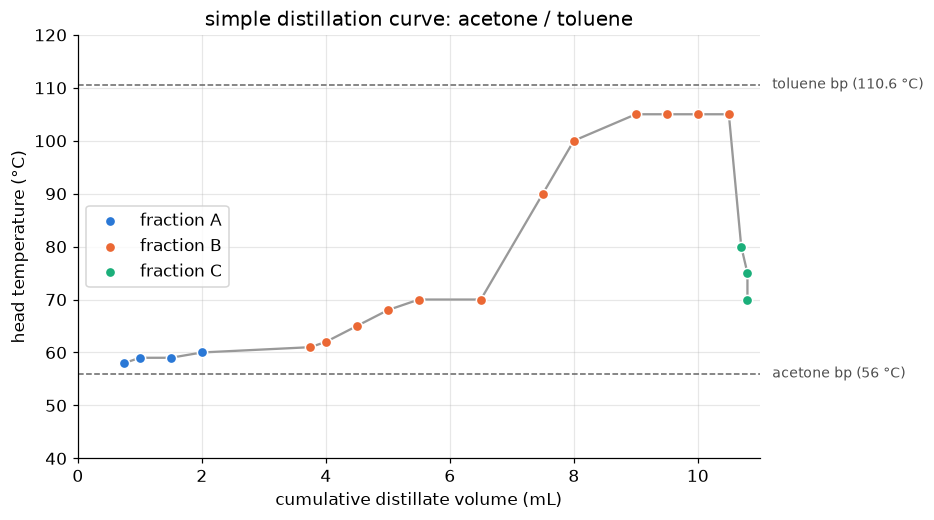

In [2]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(curve["cumulative_vol_mL"], curve["head_temp_C"], color="0.6", lw=1.5, zorder=1)
for frac, g in curve.groupby("fraction"):
    ax.scatter(g["cumulative_vol_mL"], g["head_temp_C"], s=45, color=COLORS[frac],
               label=f"fraction {frac}", zorder=2, edgecolor="white", linewidth=1)
for bp, name in [(56.0, "acetone bp (56 °C)"), (110.6, "toluene bp (110.6 °C)")]:
    ax.axhline(bp, ls="--", lw=1, color="0.4")
    ax.text(11.2, bp, name, color="0.3", fontsize=9, va="center")
ax.set(xlabel="cumulative distillate volume (mL)", ylabel="head temperature (°C)",
       title="simple distillation curve: acetone / toluene", ylim=(40, 120), xlim=(0, 11))
ax.legend(loc="center left")
fig.savefig("figures/distillation_curve.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. gc analysis + material balance

compound,acetone,toluene,vol_mL,acetone_mL,toluene_mL
sample,,,,,
A,84.15,15.85,2.0,1.68,0.32
B,36.97,63.03,8.5,3.14,5.36
C,5.06,94.94,0.3,0.02,0.28


recombined acetone: 44.82% | measured original: 46.58% | diff: -1.76 pts
volume recovery: 99.1% of 10.9 mL


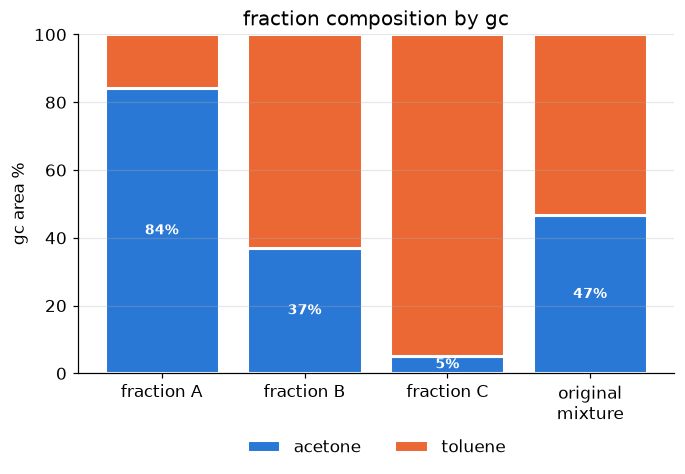

In [3]:
peaks = gc[gc["compound"] != "artifact"].copy()   # drop ipa syringe-rinse artifact
peaks["area_pct"] = peaks.groupby("sample")["area_uVs"].transform(lambda a: 100 * a / a.sum())
comp = peaks.pivot(index="sample", columns="compound", values="area_pct")
comp["vol_mL"] = gc.groupby("sample")["fraction_vol_mL"].first()

fr = comp.loc[["A", "B", "C"]].copy()
fr["acetone_mL"] = fr["vol_mL"] * fr["acetone"] / 100
fr["toluene_mL"] = fr["vol_mL"] * fr["toluene"] / 100
display(fr.round(2))

total = fr["vol_mL"].sum()
initial = total + 0.1   # + residual left in flask
calc = 100 * fr["acetone_mL"].sum() / total
meas = comp.loc["original_mixture", "acetone"]
print(f"recombined acetone: {calc:.2f}% | measured original: {meas:.2f}% | diff: {calc - meas:+.2f} pts")
print(f"volume recovery: {100 * total / initial:.1f}% of {initial:.1f} mL")

fig, ax = plt.subplots(figsize=(7, 4))
labels = ["A", "B", "C", "original_mixture"]
xlab = ["fraction A", "fraction B", "fraction C", "original\nmixture"]
a, t = comp.loc[labels, "acetone"], comp.loc[labels, "toluene"]
ax.bar(xlab, a, color=ACETONE, label="acetone", edgecolor="white", linewidth=2)
ax.bar(xlab, t, bottom=a, color=TOLUENE, label="toluene", edgecolor="white", linewidth=2)
for i, v in enumerate(a):
    ax.text(i, v / 2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
ax.set(ylabel="gc area %", title="fraction composition by gc", ylim=(0, 100))
ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
fig.savefig("figures/gc_composition.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. raoult's law T-x-y model

model pure bps: acetone 56.1 °C, toluene 110.6 °C


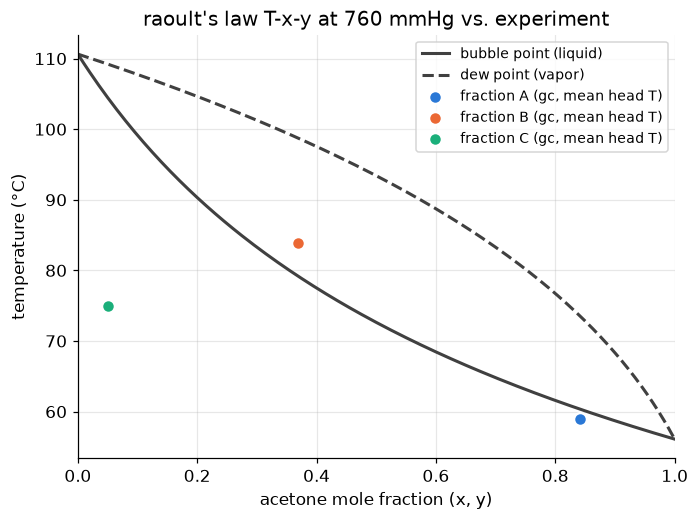

In [4]:
# antoine: log10(p*/mmHg) = A - B / (T/°C + C) 
ANTOINE = {"acetone": (7.11714, 1210.595, 229.664),
           "toluene": (6.95464, 1344.800, 219.480)}
P = 760.0  # mmHg

def psat(T, comp):
    A, B, C = ANTOINE[comp]
    return 10 ** (A - B / (T + C))

def bubble_T(x):
    # raoult + dalton: x*p_ac + (1-x)*p_tol = P  -> solve for T
    f = lambda T: x * psat(T, "acetone") + (1 - x) * psat(T, "toluene") - P
    return brentq(f, 0, 150)

x = np.linspace(0, 1, 201)
Tb = np.array([bubble_T(xi) for xi in x])
y = x * psat(Tb, "acetone") / P   # vapor in equilibrium with liquid x
print(f"model pure bps: acetone {bubble_T(1):.1f} °C, toluene {bubble_T(0):.1f} °C")

avgT = curve.groupby("fraction")["head_temp_C"].mean()
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, Tb, color="0.25", lw=2, label="bubble point (liquid)")
ax.plot(y, Tb, color="0.25", lw=2, ls="--", label="dew point (vapor)")
for frac in ["A", "B", "C"]:
    ax.scatter(fr.loc[frac, "acetone"] / 100, avgT[frac], s=70, color=COLORS[frac],
               edgecolor="white", linewidth=1.5, zorder=3, label=f"fraction {frac} (gc, mean head T)")
ax.set(xlabel="acetone mole fraction (x, y)", ylabel="temperature (°C)",
       title="raoult's law T-x-y at 760 mmHg vs. experiment", xlim=(0, 1))
ax.legend(fontsize=9)
fig.savefig("figures/txy_diagram.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. rayleigh simple-distillation model vs. experiment

,rayleigh_pred_%,gc_measured_%
A,80.9,84.2
B,40.7,37.0
C,0.0,5.1


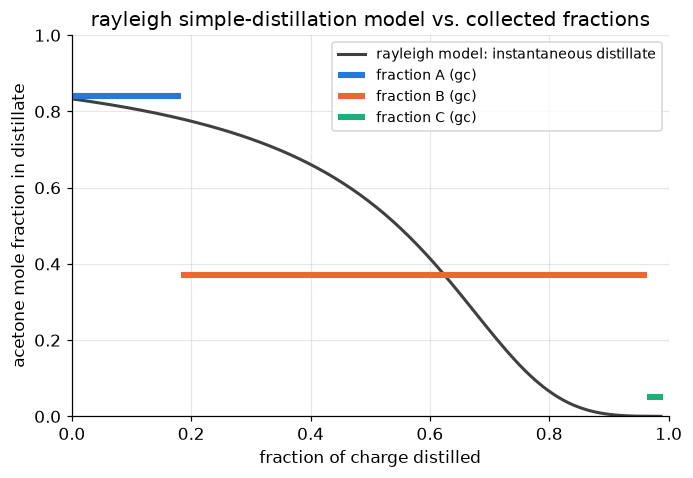

In [5]:
# ln(W/W0) = ∫ dx / (y - x), integrated from the starting pot composition x0
x0 = meas / 100
xs = np.linspace(x0, 1e-5, 5000)
ys = np.interp(xs, x, y)
W = np.exp(cumulative_trapezoid(1 / (ys - xs), xs, initial=0))   # pot moles / initial
frac_dist = 1 - W

def avg_distillate(f1, f2):
    # acetone balance on the pot between two cut points
    x1, x2 = np.interp([f1, f2], frac_dist, xs)
    W1, W2 = 1 - f1, 1 - f2
    return (W1 * x1 - W2 * x2) / (W1 - W2)

cuts = {"A": (0, 2.0), "B": (2.0, 10.5), "C": (10.5, 10.8)}   # cumulative mL at each cut
results = pd.DataFrame({k: {"rayleigh_pred_%": 100 * avg_distillate(v1 / initial, v2 / initial),
                            "gc_measured_%": fr.loc[k, "acetone"]} for k, (v1, v2) in cuts.items()}).T
display(results.round(1))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(frac_dist, ys, color="0.25", lw=2, label="rayleigh model: instantaneous distillate")
for k, (v1, v2) in cuts.items():
    ax.hlines(fr.loc[k, "acetone"] / 100, v1 / initial, v2 / initial, color=COLORS[k], lw=4,
              label=f"fraction {k} (gc)")
ax.set(xlabel="fraction of charge distilled", ylabel="acetone mole fraction in distillate",
       title="rayleigh simple-distillation model vs. collected fractions", xlim=(0, 1), ylim=(0, 1))
ax.legend(fontsize=9)
fig.savefig("figures/rayleigh_model.png", dpi=200, bbox_inches="tight")
plt.show()